# Task #2: Baseline Classification
**Question:** Which kidney waitlist candidates are most likely to die or be removed as too sick within a fixed horizon after listing?

Order: logistic regression (baseline) → Random Forest → XGBoost, all on the same split and same features.

**Before running:** set `DATA_PATH` in section 1. Column names in CONFIG already match DATA_DICTIONARY.md.

**DUA reminder:** do not commit this notebook with row-level outputs printed, and do not push saved prediction files to GitHub. Aggregate tables and figures only.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss
from xgboost import XGBClassifier

RANDOM_STATE = 42

## 1. Load data

In [ ]:
url = "https://raw.githubusercontent.com/Break-Through-Tech/Healthcare-1A-predicting-organ-transplant-waitlist-outcomes-and-optimizing-allocation/main/data/kidney_waitlist_analytic.csv.gz"
df = pd.read_csv(url)
print(df.shape)
print(df.columns.tolist())

/tmp/ipykernel_1500/1630241221.py:2: DtypeWarning: Columns (22,23,24,26,27,30) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(url)


(494862, 38)
['ON_DIALYSIS', 'A2A2B_ELIGIBILITY', 'GENDER', 'ABO', 'BMI_TCR', 'FUNC_STAT_TCR', 'INIT_STAT', 'INIT_CPRA', 'END_CPRA', 'REM_CD', 'DAYSWAIT_CHRON', 'END_STAT', 'INIT_AGE', 'DIALYSIS_DATE', 'END_DATE', 'INIT_DATE', 'ETHCAT', 'PT_CODE', 'DAYSWAIT_ALLOC', 'COMPOSITE_DEATH_DATE', 'REGION', 'WL_ID_CODE', 'PREV_TX', 'TX_DATE', 'DON_TY', 'DIAG_KI', 'MULTIORG', 'ORGAN', 'PSTATUS', 'PTIME', 'TRR_ID_CODE', 'DONOR_ID', 'LISTING_CTR_CODE', 'outcome', 'event_adverse', 'event_transplant', 'censored', 'days_to_event']


## 2. CONFIG
Column names match DATA_DICTIONARY.md. Features are the dictionary's listing-time features only; everything marked *leaky* there is excluded.

In [ ]:
OUTCOME_COL    = "outcome"      # derived from REM_CD (see data dictionary mapping)
LIST_DATE_COL  = "INIT_DATE"
END_DATE_COL   = "END_DATE"     # removal / transplant / death / cutoff date
PATIENT_ID_COL = "PT_CODE"      # one patient can have several registrations

HORIZON_DAYS = 365              # predict adverse outcome within 1 year of listing

ADVERSE       = {"died", "removed_too_sick"}                                          # label = 1
NON_ADVERSE   = {"transplanted", "transplanted_elsewhere", "removed_administrative"}  # label = 0
# Decision to confirm with team/Deepti: does removed_administrative belong in NON_ADVERSE?
DROP_OUTCOMES = {"unknown"}

# Extract cutoff. None = use the latest END_DATE among still_waiting rows (their END_DATE is the cutoff).
DATA_CUTOFF = None

# Listing-time features from the data dictionary (leaky fields excluded)
NUMERIC_FEATURES     = ["INIT_AGE", "BMI_TCR", "INIT_CPRA"]
CATEGORICAL_FEATURES = ["GENDER", "ETHCAT", "ABO", "ON_DIALYSIS", "FUNC_STAT_TCR", "INIT_STAT", "REGION"]

# Race/ethnicity as a predictor is a team decision (fairness audit later). Flip to False to drop it.
USE_ETHCAT = True

# Experiment (off for the baseline): add days on dialysis at listing, built from DIALYSIS_DATE.
# Only dialysis time BEFORE listing is used, so it isn't leaky. The dictionary lists DIALYSIS_DATE as descriptive.
USE_DIALYSIS_TIME = False

# Split: "temporal" (train on earlier listings, test on later) or "random" (stratified, grouped by patient)
SPLIT = "temporal"
TEST_START = "2021-03-15"   # kidney Acuity Circles start date; test set = post-policy listings

## 3. Build the label (handles censoring)
Why not just use the team's `event_adverse` column? It marks `still_waiting` as 0, but those candidates might still die or be removed later. The overview warns this biases the model.

Instead:
- **Eligible rows:** only registrations listed at least `HORIZON_DAYS` before the cutoff, so everyone has a full year of follow-up. (Keeping recent listings that already had an event while dropping the ones still waiting would over-sample early events.)
- **1** = died or removed too sick within `HORIZON_DAYS` of listing
- **0** = any other exit within the horizon, OR still registered at the horizon
- **Dropped** = `unknown` outcome, and exits with a negative duration (the 59 data-entry errors noted in the dictionary)

In [ ]:
d = df.copy()
d[LIST_DATE_COL] = pd.to_datetime(d[LIST_DATE_COL], errors="coerce")
d[END_DATE_COL]  = pd.to_datetime(d[END_DATE_COL],  errors="coerce")

sw = d[OUTCOME_COL] == "still_waiting"
cutoff = pd.Timestamp(DATA_CUTOFF) if DATA_CUTOFF else d.loc[sw, END_DATE_COL].max()
print("Cutoff used:", cutoff.date())
print("still_waiting END_DATE range:", d.loc[sw, END_DATE_COL].min().date(), "to", d.loc[sw, END_DATE_COL].max().date(),
      "(if these differ a lot, still_waiting END_DATE isn't a single cutoff; tell the team)")

log = {"start": len(d)}
d = d[~d[OUTCOME_COL].isin(DROP_OUTCOMES) & d[LIST_DATE_COL].notna()]
log["after dropping unknown outcome"] = len(d)

d = d[d[LIST_DATE_COL] <= cutoff - pd.Timedelta(days=HORIZON_DAYS)]
log[f"after keeping listings >= {HORIZON_DAYS}d before cutoff"] = len(d)

days_to_exit = (d[END_DATE_COL] - d[LIST_DATE_COL]).dt.days
exited = d[OUTCOME_COL].isin(ADVERSE | NON_ADVERSE)
bad = exited & (days_to_exit.isna() | (days_to_exit < 0))
d, days_to_exit = d[~bad].copy(), days_to_exit[~bad]
log["after dropping missing/negative durations"] = len(d)

d["y"] = (d[OUTCOME_COL].isin(ADVERSE) & (days_to_exit <= HORIZON_DAYS)).astype(int)

for k, v in log.items(): print(f"{k:45s} {v:>9,}")
print(f"\n1-year adverse rate (y=1): {d['y'].mean():.3f}")
if "event_adverse" in d: print(f"Team's event_adverse rate on same rows (any time, no horizon): {d['event_adverse'].mean():.3f}")
print(pd.crosstab(d[OUTCOME_COL], d["y"]))

Cutoff used: 2026-07-03
still_waiting END_DATE range: 2026-07-03 to 2026-07-03 (if these differ a lot, still_waiting END_DATE isn't a single cutoff; tell the team)
start                                           494,862
after dropping unknown outcome                  490,047
after keeping listings >= 365d before cutoff    437,417
after dropping missing/negative durations       437,361

1-year adverse rate (y=1): 0.038
Team's event_adverse rate on same rows (any time, no horizon): 0.157
y                            0     1
outcome                             
died                     24432  9636
removed_administrative   44584     0
removed_too_sick         27666  7103
still_waiting            64076     0
transplanted            223767     0
transplanted_elsewhere   36097     0


## 4. Features

In [ ]:
num_cols = list(NUMERIC_FEATURES)
cat_cols = [c for c in CATEGORICAL_FEATURES if USE_ETHCAT or c != "ETHCAT"]

if USE_DIALYSIS_TIME:
    dd = (d[LIST_DATE_COL] - pd.to_datetime(d["DIALYSIS_DATE"], errors="coerce")).dt.days
    d["dialysis_days_at_listing"] = dd.where(dd > 0, 0).fillna(0)   # missing or started after listing -> 0
    num_cols.append("dialysis_days_at_listing")

# Listing 2015+ means two eras: KAS (Dec 2014) and Acuity Circles (Mar 15, 2021)
d["policy_era"] = np.where(d[LIST_DATE_COL] >= pd.Timestamp("2021-03-15"), "acuity_circles", "KAS")
# With a temporal split, training has no Acuity Circles listings, so policy_era can't be learned.
# Only use it as a feature with the random split.
if SPLIT == "random":
    cat_cols.append("policy_era")

for c in cat_cols:   # codes like ETHCAT / REGION / INIT_STAT are categories, not numbers
    d[c] = d[c].astype(str).str.replace(r"\.0$", "", regex=True).where(d[c].notna(), np.nan)

print("Numeric:", num_cols)
print("Categorical:", cat_cols)
print(d[num_cols + cat_cols].isna().mean().round(3).sort_values(ascending=False))

Numeric: ['INIT_AGE', 'BMI_TCR', 'INIT_CPRA']
Categorical: ['GENDER', 'ETHCAT', 'ABO', 'ON_DIALYSIS', 'FUNC_STAT_TCR', 'INIT_STAT', 'REGION']
INIT_CPRA        0.227
BMI_TCR          0.003
FUNC_STAT_TCR    0.001
INIT_AGE         0.000
ETHCAT           0.000
GENDER           0.000
ABO              0.000
ON_DIALYSIS      0.000
INIT_STAT        0.000
REGION           0.000
dtype: float64


## 5. Train/test split
Train on listings before `TEST_START`, test on listings after. This is harder than a random split, but it's the honest one: the model gets judged on patients it would actually be used on, after a policy change.

In [ ]:
from sklearn.model_selection import train_test_split, GroupShuffleSplit
if SPLIT == "temporal":
    is_test = (d[LIST_DATE_COL] >= pd.Timestamp(TEST_START)).values
else:
    if PATIENT_ID_COL:   # keep all listings of one patient on the same side
        gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
        _, te = next(gss.split(d, d["y"], groups=d[PATIENT_ID_COL]))
    else:
        _, te = train_test_split(np.arange(len(d)), test_size=0.2, stratify=d["y"], random_state=RANDOM_STATE)
    is_test = np.zeros(len(d), dtype=bool); is_test[te] = True
X_train, y_train = d.loc[~is_test, num_cols + cat_cols], d.loc[~is_test, "y"]
X_test,  y_test  = d.loc[ is_test, num_cols + cat_cols], d.loc[ is_test, "y"]
print(f"Train: {len(X_train):,} rows, adverse rate {y_train.mean():.3f}")
print(f"Test:  {len(X_test):,} rows, adverse rate {y_test.mean():.3f}")

Train: 236,942 rows, adverse rate 0.039
Test:  200,419 rows, adverse rate 0.038


## 6. Preprocessing + models
Preprocessing is fit on the **training set only**, inside the pipeline, so nothing from the test set leaks in.

No class weighting on purpose: weighting distorts predicted probabilities, and Task #4 (calibration / Brier) needs honest probabilities. PR-AUC and ROC-AUC don't need weighting.

In [ ]:
preprocess = ColumnTransformer(sparse_threshold=0, transformers=[
    ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                      ("scale", StandardScaler())]), num_cols),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])

models = {
    "LogisticRegression": LogisticRegression(max_iter=2000),
    "RandomForest": RandomForestClassifier(n_estimators=300, min_samples_leaf=50,
                                           n_jobs=-1, random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=5,
                             subsample=0.8, colsample_bytree=0.8, eval_metric="aucpr",
                             n_jobs=-1, random_state=RANDOM_STATE),
}

fitted, test_probs = {}, {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    test_probs[name] = pipe.predict_proba(X_test)[:, 1]
    print("done:", name)

done: LogisticRegression
done: RandomForest
done: XGBoost


## 7. Evaluate (PR-AUC first, since the positive class is rare)

In [ ]:
def top_decile_lift(y, p):
    y = np.asarray(y)
    k = max(1, int(np.ceil(0.10 * len(y))))
    top = np.argsort(-p)[:k]
    return y[top].mean() / y.mean()

prevalence = y_test.mean()
rows = []
for name, p in test_probs.items():
    rows.append({"model": name,
                 "PR_AUC": average_precision_score(y_test, p),
                 "ROC_AUC": roc_auc_score(y_test, p),
                 "Brier": brier_score_loss(y_test, p),
                 "top_decile_lift": top_decile_lift(y_test, p)})
results = pd.DataFrame(rows).set_index("model").round(3)
print(f"Test prevalence = {prevalence:.3f}  (a random model's PR-AUC is about this)")
print(f"Brier of always predicting the prevalence = {prevalence*(1-prevalence):.3f}")
print("Targets: PR-AUC >= 0.65, ROC-AUC >= 0.78, Brier <= 0.18, lift >= 2.5x")
results

Test prevalence = 0.038  (a random model's PR-AUC is about this)
Brier of always predicting the prevalence = 0.037
Targets: PR-AUC >= 0.65, ROC-AUC >= 0.78, Brier <= 0.18, lift >= 2.5x


,PR_AUC,ROC_AUC,Brier,top_decile_lift
model,,,,
LogisticRegression,0.083,0.662,0.036,2.411
RandomForest,0.084,0.668,0.036,2.469
XGBoost,0.083,0.668,0.036,2.428


## 8. Does performance hold up over time?
Breaks the test set down by listing year. With the random split, this also shows whether performance differs before vs. after the 2014 and 2021 policy changes.

In [ ]:
yr = d.loc[is_test, LIST_DATE_COL].dt.year.values
best = results["PR_AUC"].idxmax()
by_year = []
for y_ in sorted(np.unique(yr)):
    m = yr == y_
    if y_test[m].nunique() == 2:
        by_year.append({"year": y_, "n": int(m.sum()), "adverse_rate": y_test[m].mean(),
                        f"{best}_PR_AUC": average_precision_score(y_test[m], test_probs[best][m]),
                        f"{best}_ROC_AUC": roc_auc_score(y_test[m], test_probs[best][m])})
pd.DataFrame(by_year).round(3)

,year,n,adverse_rate,RandomForest_PR_AUC,RandomForest_ROC_AUC
0,2021,34037,0.042,0.097,0.675
1,2022,44003,0.038,0.087,0.668
2,2023,46608,0.036,0.080,0.671
3,2024,49323,0.039,0.082,0.663
4,2025,26448,0.034,0.072,0.660


## 9. What the baseline learned (logistic regression coefficients)

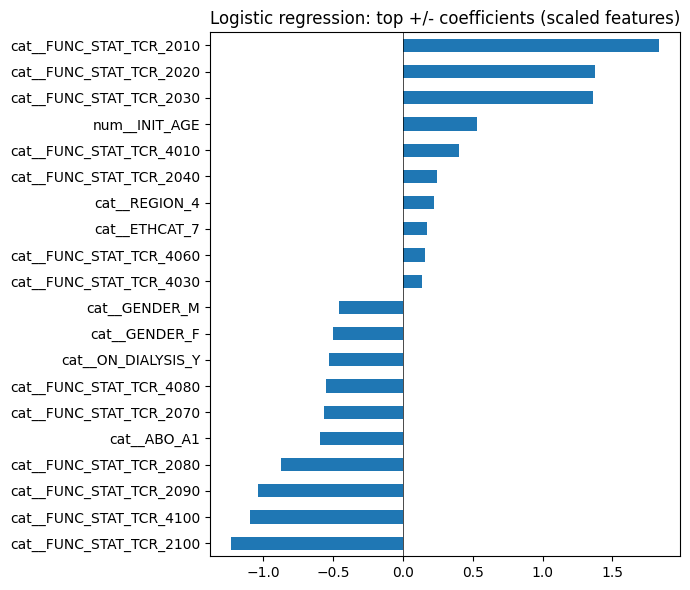

In [ ]:
lr = fitted["LogisticRegression"]
names = lr.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lr.named_steps["model"].coef_[0], index=names).sort_values()
top = pd.concat([coefs.head(10), coefs.tail(10)])
top.plot.barh(figsize=(7, 6)); plt.title("Logistic regression: top +/- coefficients (scaled features)")
plt.axvline(0, color="k", lw=0.5); plt.tight_layout(); plt.show()

## 10. Save test predictions for Task #4 (calibration)
Saves to Drive, **not** the repo (row-level data, DUA).

In [ ]:
# preds = pd.DataFrame({"y_true": y_test.values, **{f"p_{k}": v for k, v in test_probs.items()}})
# preds.to_csv("/content/drive/MyDrive/PATH/task2_test_predictions.csv", index=False)

## 10. Findings (task 2)


**Label:** 1 = died or removed as too sick within 365 days of listing, 0 = otherwise. Only listings made at least 1 year before the data cutoff (2026-07-03) are used, so every candidate has full follow-up. Final cohort: 437,361 registrations, 3.8% adverse. The team's event_adverse column gives 15.7% on the same rows because it counts still_waiting as 0, which ignores censoring.

**Split:** trained on listings before 2021-03-15 (236,942 rows), tested on listings after the Acuity Circles policy change (200,419 rows).

**Features:** 10 listing-time features from the data dictionary. Leaky transplant-time fields excluded.

| Model | PR-AUC | ROC-AUC | Brier | Top-decile lift |
|---|---|---|---|---|
| Logistic Regression (baseline) | 0.083 | 0.662 | 0.036 | 2.41 |
| Random Forest | 0.084 | 0.668 | 0.036 | 2.47 |
| XGBoost | 0.083 | 0.668 | 0.036 | 2.43 |

**Main finding:** Random Forest and XGBoost barely beat logistic regression (within 0.006 on every metric). The signal in these listing-time features is mostly simple and additive, so the extra complexity doesn't help.

**Against targets:** PR-AUC is about 2.2x the random baseline (0.038) but far below 0.65. ROC-AUC (0.66) misses 0.78. Top-decile lift (2.41–2.47) is just under 2.5. Brier (0.036) meets ≤ 0.18, but predicting 3.8% for everyone already scores 0.037, so this target is met without the model adding much.

**Over time:** ROC-AUC stayed at 0.66–0.68 in every test year (2021–2025). PR-AUC dropped from 0.097 to 0.072, but the adverse rate also fell (4.2% to 3.4%), so much of that drift reflects fewer adverse events.

**Strongest predictor:** functional status at registration. Worse function means higher risk, which is clinically sensible.

**Caveat:** label 0 includes candidates transplanted quickly, and transplant speed depends on allocation (blood type, CPRA, region). Part of what the model learns may be allocation patterns, not only clinical risk.